Importación de librerías


In [1]:
#Importación de librerias a utilizar
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


Importación de datos

In [2]:
#Importacion de la base de datos. Contiene informacion personal de comensales, preferencias alimentarias, frecuencia de asistencia
db_restaurant ='../data/base_datos_restaurantes_USA_v2.csv'
dt_restaurant=pd.read_csv(db_restaurant, encoding= 'utf-8')

#Se verifica que se haya cargado correctamente el archivo
print(dt_restaurant.head())

   id_persona    nombre apellido  edad     genero ciudad_residencia  \
0  2550327378   Jackson    Gomez  31.0  Masculino             Miami   
1  9446112038  Samantha     Soto  40.0   Femenino            Denver   
2  3098363243     Terry    Adams  62.0   Femenino            Denver   
3  4013002847     James  Shannon  41.0  Masculino            Boston   
4  7372911048     Susan    Jones  49.0   Femenino         San Diego   

  estrato_socioeconomico  frecuencia_visita  promedio_gasto_comida ocio  \
0                   Alto                  6                  67.51   Sí   
1                  Medio                  2                  44.92   Sí   
2                   Bajo                  2                   9.24   Sí   
3                   Alto                  5                  30.74   Sí   
4                   Bajo                  0                   0.00   No   

  consume_licor preferencias_alimenticias membresia_premium telefono_contacto  \
0            No               Vegetariano

Verificación de datos

In [ ]:
general_info= dt_restaurant.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  28597 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          14834 non-null  str    
 14  c

Revision de duplicados

In [ ]:
Duplicated_Rows = dt_restaurant[dt_restaurant.duplicated(subset=['id_persona'])]
print("Duplicated data:", Duplicated_Rows)

#Como no se encuentran datos duplicados de clientes, no se reliza ninguna acción, en caso positivo, agregar un bloque para las funciones de eliminación

Duplicated data: Empty DataFrame
Columns: [id_persona, nombre, apellido, edad, genero, ciudad_residencia, estrato_socioeconomico, frecuencia_visita, promedio_gasto_comida, ocio, consume_licor, preferencias_alimenticias, membresia_premium, telefono_contacto, correo_electronico, tipo_de_pago_mas_usado, ingresos_mensuales]
Index: []


Limpieza de datos

In [ ]:
#Se revisan los min y max para las columnas cuantitativas del dataframe
dt_restaurant.describe()


,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.000000e+04,29899.000000,30000.000000,29855.000000,30000.000000
mean,5.504765e+09,49.665006,3.896133,32.603452,5389.755867
std,2.602799e+09,23.839550,2.741532,26.402601,4538.491728
min,1.000153e+09,-5.000000,-3.000000,0.000000,800.000000
25%,3.243617e+09,33.000000,2.000000,13.290000,1860.000000
50%,5.515865e+09,49.000000,4.000000,25.510000,3402.000000
75%,7.754426e+09,65.000000,5.000000,44.400000,7761.000000
max,9.999627e+09,300.000000,10.000000,149.970000,17999.000000


In [6]:
#Se identifican los valores negativos e ilógicos en 'edad' y se remplaza por nulos
cond1 = (dt_restaurant['edad']<0) | (dt_restaurant['edad']> 100)
dt_restaurant.loc[cond1, 'edad'] = np.nan

In [7]:
#Se identifican los valores negativos en frecuencia y se cambian por nulos
cond2 = (dt_restaurant['frecuencia_visita']<0)
dt_restaurant.loc[cond2, 'frecuencia_visita'] = np.nan

In [8]:
#Se verifican los datos nuevamente, dan valores aceptables
dt_restaurant.describe()

,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.000000e+04,29692.000000,28453.000000,29855.000000,30000.000000
mean,5.504765e+09,48.916173,4.271079,32.603452,5389.755867
std,2.602799e+09,18.160132,2.279979,26.402601,4538.491728
min,1.000153e+09,18.000000,0.000000,0.000000,800.000000
25%,3.243617e+09,33.000000,3.000000,13.290000,1860.000000
50%,5.515865e+09,49.000000,4.000000,25.510000,3402.000000
75%,7.754426e+09,65.000000,6.000000,44.400000,7761.000000
max,9.999627e+09,80.000000,10.000000,149.970000,17999.000000


In [9]:
#Se verifica que todas las ciudades correspondan a un unico valor, preguntar si se tiene que hacer para nombres y apellido cuando se ve aparentemente bien
dt_restaurant['ciudad_residencia'].value_counts().sort_index(ascending=True)

ciudad_residencia
Boston       2547
Chicago      5384
Dallas       2602
Denver       2523
Houston      2212
Miami        3186
NYC          4769
Phoenix      1511
San Diego    3075
Seattle      2191
Name: count, dtype: int64

Null Values o datos vacíos

In [ ]:
#Porcentaje de datos vacíos
Percentage_Null = dt_restaurant.isna().mean()*100
print(Percentage_Null)

id_persona                    0.000000
nombre                        0.000000
apellido                      0.000000
edad                          1.026667
genero                        0.000000
ciudad_residencia             0.000000
estrato_socioeconomico        0.000000
frecuencia_visita             5.156667
promedio_gasto_comida         0.483333
ocio                          0.000000
consume_licor                 0.000000
preferencias_alimenticias     4.676667
membresia_premium             0.000000
telefono_contacto            50.553333
correo_electronico           50.240000
tipo_de_pago_mas_usado        0.000000
ingresos_mensuales            0.000000
dtype: float64


In [11]:
#Visualización del dataframe
dt_restaurant

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6.0,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2.0,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2.0,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5.0,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0.0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,4862097674,Robert,Cortez,20.0,Masculino,Houston,Alto,NaN,30.82,Sí,Sí,Vegano,Sí,NaN,garciagregory@example.net,Tarjeta,5781
29996,9458262482,Michael,Holt,78.0,Masculino,Denver,Alto,5.0,45.04,No,No,Mariscos,No,NaN,jimmy77@example.org,Efectivo,7652
29997,3412365931,Rebecca,Henry,77.0,Femenino,San Diego,Muy Alto,7.0,93.55,No,Sí,Mariscos,Sí,NaN,NaN,Efectivo,12639
29998,8853079811,Tamara,Griffin,77.0,Femenino,Chicago,Bajo,1.0,6.18,Sí,No,Otro,No,(243)658-6543x11668,NaN,Tarjeta,1057


In [12]:
#Se rellena los valores nulos con la mediana
dt_restaurant['edad']=dt_restaurant['edad'].fillna(dt_restaurant['edad'].median())

#Se modifica el tipo de variable para edad
dt_restaurant['edad'] = dt_restaurant['edad'].astype(int)

In [13]:
#Se rellena los valores nulos con la mediana
dt_restaurant['frecuencia_visita']=dt_restaurant['frecuencia_visita'].fillna(dt_restaurant['frecuencia_visita'].median())

In [14]:
#Se rellena los valores nulos con la mediana
dt_restaurant['promedio_gasto_comida']=dt_restaurant['promedio_gasto_comida'].fillna(dt_restaurant['promedio_gasto_comida'].median())

In [ ]:
#Se rellena los valores nulos con 'desconocido' para no inventar informacion falsa
dt_restaurant['telefono_contacto']=dt_restaurant['telefono_contacto'].fillna('Desconocido')

In [ ]:
#Se rellena los valores nulos con 'desconocido' para no inventar informacion falsa
dt_restaurant['correo_electronico']=dt_restaurant['correo_electronico'].fillna('Desconocido')

In [ ]:
#Se rellena los valores nulos con 'desconocido' para no inventar informacion falsa
dt_restaurant['preferencias_alimenticias']=dt_restaurant['preferencias_alimenticias'].fillna('Desconocido')

In [18]:
#Se verifica que la información está completa
Percentage_Null = dt_restaurant.isna().mean()*100
print(Percentage_Null)

id_persona                   0.0
nombre                       0.0
apellido                     0.0
edad                         0.0
genero                       0.0
ciudad_residencia            0.0
estrato_socioeconomico       0.0
frecuencia_visita            0.0
promedio_gasto_comida        0.0
ocio                         0.0
consume_licor                0.0
preferencias_alimenticias    0.0
membresia_premium            0.0
telefono_contacto            0.0
correo_electronico           0.0
tipo_de_pago_mas_usado       0.0
ingresos_mensuales           0.0
dtype: float64


Estandarización de datos tipo str

In [ ]:
#Se dejan los datos tipo str para hacer más fáciles los análisis y evitar error en digitacion
Columns_Text = dt_restaurant.select_dtypes(include=[str]).columns
Col_tex=Columns_Text.drop(['telefono_contacto','correo_electronico'])
#print(Col_tex)
for col in Col_tex:
    dt_restaurant[col]=dt_restaurant[col].astype(str).str.strip().str.lower()
    
print(dt_restaurant)

       id_persona    nombre apellido  edad     genero ciudad_residencia  \
0      2550327378   jackson    gomez    31  masculino             miami   
1      9446112038  samantha     soto    40   femenino            denver   
2      3098363243     terry    adams    62   femenino            denver   
3      4013002847     james  shannon    41  masculino            boston   
4      7372911048     susan    jones    49   femenino         san diego   
...           ...       ...      ...   ...        ...               ...   
29995  4862097674    robert   cortez    20  masculino           houston   
29996  9458262482   michael     holt    78  masculino            denver   
29997  3412365931   rebecca    henry    77   femenino         san diego   
29998  8853079811    tamara  griffin    77   femenino           chicago   
29999  4553644223    tracey    flynn    57   femenino           chicago   

      estrato_socioeconomico  frecuencia_visita  promedio_gasto_comida ocio  \
0                   

Información filtrada por ciudad

In [20]:
#Revisar la lista de ciudades para filtrar
dt_restaurant['ciudad_residencia'].unique()

<StringArray>
[    'miami',    'denver',    'boston', 'san diego',    'dallas',       'nyc',
   'seattle',   'chicago',   'houston',   'phoenix']
Length: 10, dtype: str

In [21]:
#Si desea cambiar la ciudad, sólo escriba el nombre dentro de las comillas en la variable "city"
#Se realiza una copia para que la original no se vea afectada por la agregación de columnas nuevas en las tablas posteriores
city = 'denver'
dt_restaurant_filtered= dt_restaurant.loc[dt_restaurant['ciudad_residencia'] == city].copy()
print(dt_restaurant_filtered)

       id_persona    nombre  apellido  edad     genero ciudad_residencia  \
1      9446112038  samantha      soto    40   femenino            denver   
2      3098363243     terry     adams    62   femenino            denver   
14     1885294397   spencer  thompson    79  masculino            denver   
20     7832305686      lisa    powell    43   femenino            denver   
57     2067843621   barbara      reid    73   femenino            denver   
...           ...       ...       ...   ...        ...               ...   
29929  1429319986     jenna      dunn    71   femenino            denver   
29934  8646464809      lori     brown    20   femenino            denver   
29962  4608515250    angela    martin    51   femenino            denver   
29973  3941033980    janice    murray    57   femenino            denver   
29996  9458262482   michael      holt    78  masculino            denver   

      estrato_socioeconomico  frecuencia_visita  promedio_gasto_comida ocio  \
1       

Tablas preliminares para análisis

In [ ]:
#1.Tabla de Genero para la ciudad de Denver
Dic_genre=dict(Cantidad = dt_restaurant_filtered['genero'].value_counts(), Porcentaje = dt_restaurant_filtered['genero'].value_counts(normalize = True)*100)
Genre_Table = pd.DataFrame(Dic_genre)
Genre_Table.loc['Total']=Genre_Table.sum()
print(Genre_Table)


           Cantidad  Porcentaje
genero                         
femenino     1282.0   50.812525
masculino    1241.0   49.187475
Total        2523.0  100.000000


In [ ]:
#2.Tabla de edad para la ciudad de Denver
#Numero de intervalos ideales de acuerdo a la regla de Sturges
K = int(1 + np.log2(len(dt_restaurant_filtered['edad'])))
intervals_aprox = np.round(np.linspace(dt_restaurant_filtered["edad"].min(), dt_restaurant_filtered["edad"].max(),K + 1,))
#Se crea la columa 'Rango edad' para contabilizar los que tienen esas edades
dt_restaurant_filtered['Rango_edad'] = pd.cut(dt_restaurant_filtered['edad'], bins=intervals_aprox, right=False)

Dic_Age=dict(Cantidad = dt_restaurant_filtered['Rango_edad'].value_counts(), Porcentaje = dt_restaurant_filtered['Rango_edad'].value_counts(normalize = True)*100)
#Se crea el dataframe y se organizan los datos
Age_Table = pd.DataFrame(Dic_Age).sort_index()
Age_Table.loc['Total']=Age_Table.sum()
print(Age_Table)


              Cantidad  Porcentaje
Rango_edad                        
[18.0, 23.0)     192.0    7.707748
[23.0, 28.0)     175.0    7.025291
[28.0, 34.0)     208.0    8.350060
[34.0, 39.0)     199.0    7.988760
[39.0, 44.0)     215.0    8.631072
[44.0, 49.0)     213.0    8.550783
[49.0, 54.0)     245.0    9.835407
[54.0, 59.0)     215.0    8.631072
[59.0, 64.0)     184.0    7.386592
[64.0, 70.0)     241.0    9.674829
[70.0, 75.0)     191.0    7.667603
[75.0, 80.0)     213.0    8.550783
Total           2491.0  100.000000


In [ ]:
#3. Tabla de preferencias alimenticias
Dic_food=dict(Cantidad = dt_restaurant_filtered['preferencias_alimenticias'].value_counts(), Porcentaje = dt_restaurant_filtered['preferencias_alimenticias'].value_counts(normalize = True)*100)
Food_Table = pd.DataFrame(Dic_food)
Food_Table.loc['Total']=Food_Table.sum()
print(Food_Table)

#La carne y la comida vegetariana representa el 49.9% de las preferencias alimenticias de los comensales

                           Cantidad  Porcentaje
preferencias_alimenticias                      
carnes                        632.0   25.049544
vegetariano                   626.0   24.811732
mariscos                      468.0   18.549346
vegano                        258.0   10.225922
pescado                       249.0    9.869203
otro                          172.0    6.817281
desconocido                   118.0    4.676972
Total                        2523.0  100.000000


In [ ]:
#4. Tabla de estrato socioeconómico
Dic_estrato=dict(Cantidad = dt_restaurant_filtered['estrato_socioeconomico'].value_counts(), Porcentaje = dt_restaurant_filtered['estrato_socioeconomico'].value_counts(normalize = True)*100)
Estrato_Table = pd.DataFrame(Dic_estrato)
order_est = ['bajo', 'medio', 'alto', 'muy alto']
Estrato_Table.index = pd.Categorical(Estrato_Table.index, categories=order_est, ordered=True)
Estrato_Table=Estrato_Table.sort_index()
Estrato_Table.loc['Total']=Estrato_Table.sum()
print(Estrato_Table)

          Cantidad  Porcentaje
bajo         505.0   20.015854
medio        764.0   30.281411
alto         848.0   33.610781
muy alto     406.0   16.091954
Total       2523.0  100.000000


In [ ]:
#5.Tabla frecuencia de visitas
Dic_visit=dict(Cantidad = dt_restaurant_filtered['frecuencia_visita'].value_counts(), Porcentaje = dt_restaurant_filtered['frecuencia_visita'].value_counts(normalize = True)*100)
Visit_Table = pd.DataFrame(Dic_visit)
Visit_Table.loc['Total']=Visit_Table.sum()
print(Visit_Table)

                   Cantidad  Porcentaje
frecuencia_visita                      
4.0                   573.0   22.711058
5.0                   512.0   20.293302
2.0                   348.0   13.793103
6.0                   313.0   12.405866
3.0                   301.0   11.930242
1.0                   113.0    4.478795
0.0                   104.0    4.122077
8.0                    74.0    2.933016
9.0                    62.0    2.457392
7.0                    62.0    2.457392
10.0                   61.0    2.417757
Total                2523.0  100.000000


In [ ]:
#6.Tabla de gastos

#Numero de intervalos ideales de acuerdo a la regla de Sturges
K = int(1 + np.log2(len(dt_restaurant_filtered['promedio_gasto_comida'])))
dt_restaurant_filtered['Rango_gasto'] = pd.cut(dt_restaurant_filtered['promedio_gasto_comida'], bins=K, right=False)

Dic_expense=dict(Cantidad = dt_restaurant_filtered['Rango_gasto'].value_counts(), Porcentaje = dt_restaurant_filtered['Rango_gasto'].value_counts(normalize = True)*100)
#Se crea el dataframe y se organizan los datos
Expence_Table = pd.DataFrame(Dic_expense).sort_index()
Expence_Table.loc['Total']=Age_Table.sum()
print(Expence_Table)

# El 74.6% de los gastos promedios de los comensales van desde el rango de [0-45] dolares, 
# con esto se puede dar una idea de los productos a escoger con los precios sugeridos
#  complementar el de los valores atipicos con los valores en las tablas de describe()

                    Cantidad  Porcentaje
Rango_gasto                             
[0.0, 11.198)          578.0   22.909235
[11.198, 22.395)       473.0   18.747523
[22.395, 33.592)       423.0   16.765755
[33.592, 44.79)        409.0   16.210860
[44.79, 55.988)        146.0    5.786762
[55.988, 67.185)       174.0    6.896552
[67.185, 78.382)       153.0    6.064209
[78.382, 89.58)         33.0    1.307967
[89.58, 100.778)        37.0    1.466508
[100.778, 111.975)      44.0    1.743956
[111.975, 123.172)      23.0    0.911613
[123.172, 134.504)      30.0    1.189061
Total                 4982.0  200.000000


In [ ]:
#7.Tabla de ingresos mensuales
K = int(1 + np.log2(len(dt_restaurant_filtered['ingresos_mensuales'])))
dt_restaurant_filtered['Rango_ingreso'] = pd.cut(dt_restaurant_filtered['ingresos_mensuales'], bins=K, right=False)

Dic_income=dict(Cantidad = dt_restaurant_filtered['Rango_ingreso'].value_counts(), Porcentaje = dt_restaurant_filtered['Rango_ingreso'].value_counts(normalize = True)*100)
#Se crea el dataframe y se organizan los datos
Income_Table = pd.DataFrame(Dic_income).sort_index()
Income_Table.loc['Total']=Income_Table.sum()
print(Income_Table)

#El 30.1% gana entre 800 y 2233 dolares y el 21.1% gana entre 2233 3665 al mes

                        Cantidad  Porcentaje
Rango_ingreso                               
[802.0, 2233.583)          760.0   30.122870
[2233.583, 3665.167)       533.0   21.125644
[3665.167, 5096.75)        221.0    8.759413
[5096.75, 6528.333)        215.0    8.521601
[6528.333, 7959.917)       218.0    8.640507
[7959.917, 9391.5)         180.0    7.134364
[9391.5, 10823.083)         55.0    2.179945
[10823.083, 12254.667)      70.0    2.774475
[12254.667, 13686.25)       64.0    2.536663
[13686.25, 15117.833)       60.0    2.378121
[15117.833, 16549.417)      73.0    2.893381
[16549.417, 17998.179)      74.0    2.933016
Total                     2523.0  100.000000


In [ ]:
#8.Tabla de consumo de licor
Dic_licor=dict(Cantidad = dt_restaurant_filtered['consume_licor'].value_counts(), Porcentaje = dt_restaurant_filtered['consume_licor'].value_counts(normalize = True)*100)
Licor_Table = pd.DataFrame(Dic_licor)
Licor_Table.loc['Total']=Licor_Table.sum()
print(Licor_Table)
#El 59.5% de los comensales comsumen licor

               Cantidad  Porcentaje
consume_licor                      
sí               1501.0   59.492667
no               1022.0   40.507333
Total            2523.0  100.000000


Interpretación de gráficos y métricas

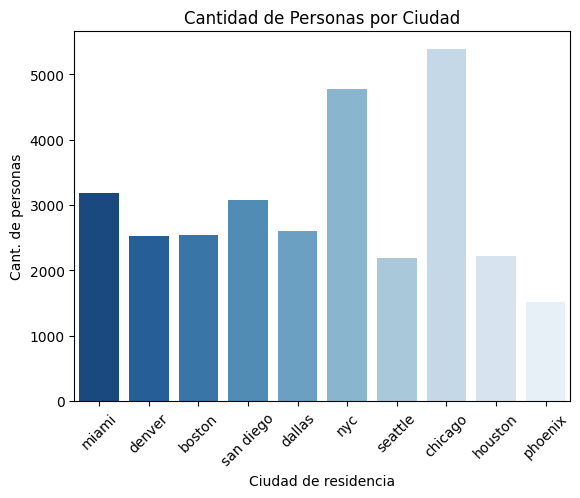

In [49]:
#Diagrama de barras por ciudad
sns.barplot(dt_restaurant, x='ciudad_residencia', y='id_persona', hue='ciudad_residencia',palette='Blues_r', estimator=len, errorbar=None)
plt.title("Cantidad de Personas por Ciudad")
plt.xlabel('Ciudad de residencia')
plt.ylabel('Cant. de personas')
plt.xticks(rotation=45)
plt.show()

#Las ciudades con mayor cantidad de personas son Chicago, NYC, Miami


Listado

In [31]:
#Lista de como se distribuyen las personas en los estratos socioeconómicos
#Si no llega haber algun dato en alguna categoría el observed false devuelve 0

Dic_class=dict(Cantidad_de_personas= dt_restaurant['estrato_socioeconomico'].value_counts(), Porcentaje = dt_restaurant['estrato_socioeconomico'].value_counts(normalize = True)*100)
SocialClass_List = pd.DataFrame(Dic_class)
order_est = ['bajo', 'medio', 'alto', 'muy alto']
SocialClass_List.index = pd.Categorical(SocialClass_List.index, categories=order_est, ordered=True)
SocialClass_List=SocialClass_List.sort_index()
SocialClass_List.index.name = 'Estrato Socioeconómico'
SocialClass_List.loc['Total']=SocialClass_List.sum()

print(SocialClass_List)

#Aun si se amplia la muestra, permanece la tendencia que predominan la mayoria de perosnas en estrato medio alto, 61.1%

                        Cantidad_de_personas  Porcentaje
Estrato Socioeconómico                                  
bajo                                  6161.0   20.536667
medio                                 9325.0   31.083333
alto                                  9038.0   30.126667
muy alto                              5476.0   18.253333
Total                                30000.0  100.000000


Gráficos

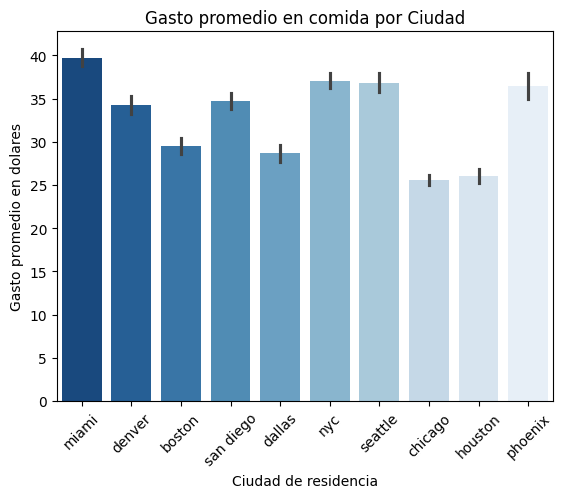

In [48]:
#ciudades en las que más se gasta dinero en promedio en restaurante al mes
sns.barplot(dt_restaurant, x='ciudad_residencia', y='promedio_gasto_comida', hue='ciudad_residencia',palette='Blues_r')
plt.title("Gasto promedio en comida por Ciudad")
plt.xlabel('Ciudad de residencia')
plt.ylabel('Gasto promedio en dolares')
plt.xticks(rotation=45)
plt.show()

#Tienen mayor consumo promedio Miami, NYC y Phoenix y menor gasto en chicago y houston. Pese a que los datos no vaian mucho de su media(barra negra) 
#Se observa que el consumo es mucho mayor en Miami y phonix que en chicago, pese a que en este último haya más habitantes (Pdría indicar una no correlacione 
#entre ventas y cantidad de persona en ciudad)

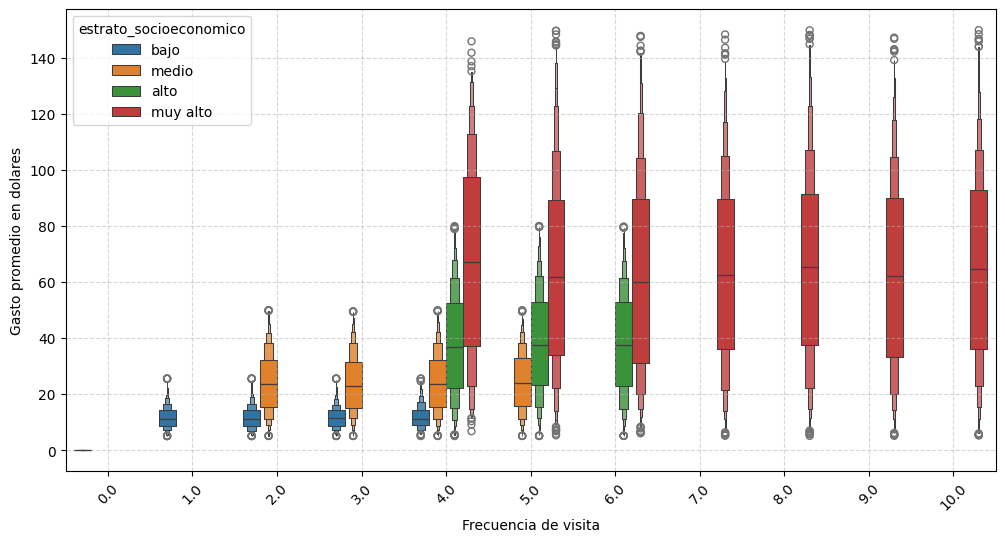

In [33]:
#Gráfico de caja y bigotes: Relación entre frecuencia de visita a los restaurantes y gasto promedio por comida según estrato socioeconómico
order_est = ['bajo', 'medio', 'alto', 'muy alto']
plt.figure(figsize=(12, 6))
sns.boxenplot(dt_restaurant,x='frecuencia_visita', y='promedio_gasto_comida',hue='estrato_socioeconomico', hue_order=order_est)
plt.xlabel('Frecuencia de visita')
plt.ylabel('Gasto promedio en dolares')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

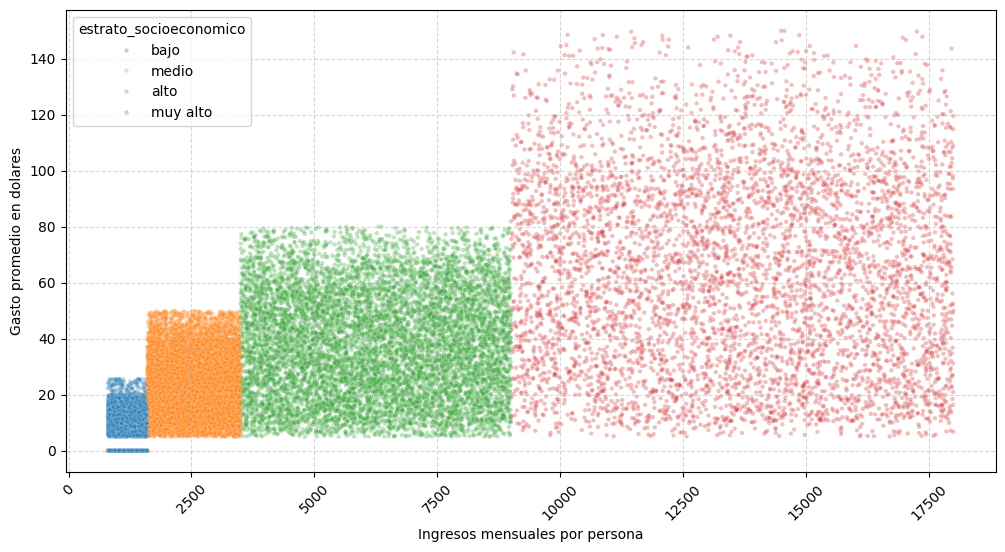

In [34]:
#Grafico de disperión: Relación entre gasto promedio mensual de todas las personas y sus ingresos mensuales
plt.figure(figsize=(12, 6))
sns.scatterplot(dt_restaurant, x='ingresos_mensuales', y='promedio_gasto_comida', hue='estrato_socioeconomico',hue_order=order_est, alpha=0.3, s=10 )
plt.xlabel('Ingresos mensuales por persona')
plt.ylabel('Gasto promedio en dolares')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

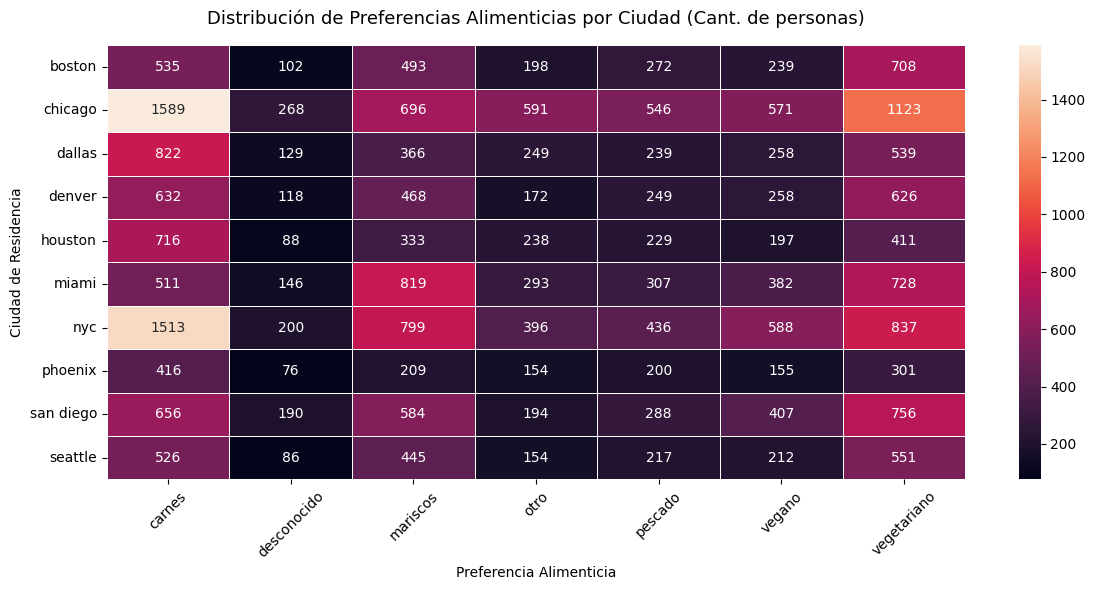

In [37]:
#Heatmap: cómo se distribuyen las preferencias alimenticias en todas las ciudades
#para poder contrastar muchas opciones de manera concisa
Cross_Table= pd.crosstab(dt_restaurant['ciudad_residencia'],dt_restaurant['preferencias_alimenticias'])
plt.figure(figsize=(12, 6))
sns.heatmap(data=Cross_Table, annot=True, linewidths=0.5, fmt='d')
plt.title('Distribución de Preferencias Alimenticias por Ciudad (Cant. de personas)', fontsize=13, pad=15)
plt.xlabel('Preferencia Alimenticia')
plt.ylabel('Ciudad de Residencia')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

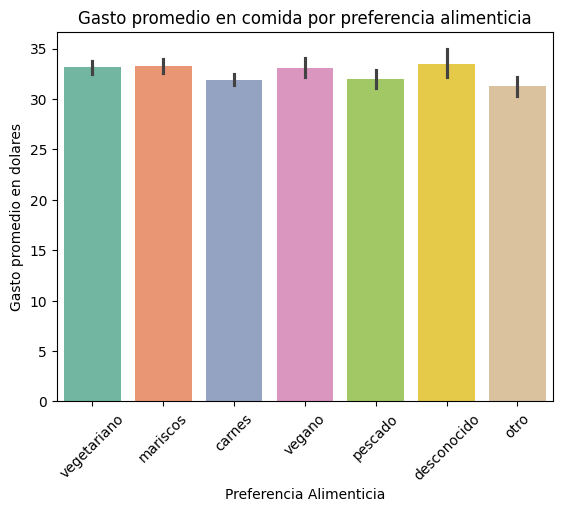

In [ ]:
#Grafico de barras: Perfilar clientes de mayor gasto: Preferencia de comida, gasto mensual
#Para una decision de negocios más fácil para personas agenas al análisis estadístico

sns.barplot(dt_restaurant, x='preferencias_alimenticias', y='promedio_gasto_comida', hue='preferencias_alimenticias',palette='Set2')
plt.title("Gasto promedio en comida por preferencia alimenticia")
plt.xlabel('Preferencia Alimenticia')
plt.ylabel('Gasto promedio en dolares')
plt.xticks(rotation=45)
plt.show()

#La prefeerencia alimenticia no es una variable de efecto causal sobre el gasto en promedio, ya que independientemente de deltipo de comida
# el gasto se mantiene en promedio entre $30-$35 con una desviacion aprox de hasta $2


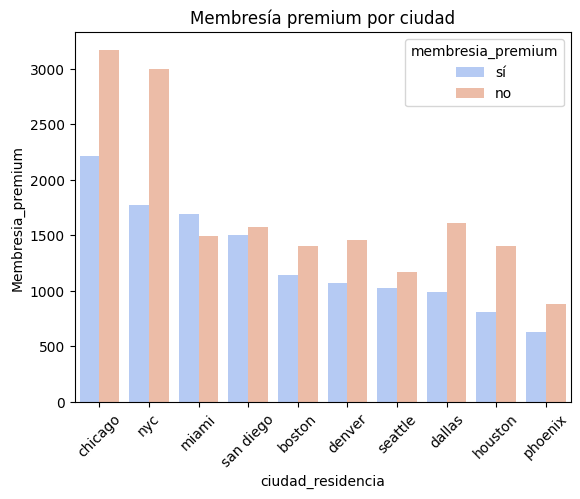

In [60]:
#Diagrama de barras para cliente premium se utiliza countplot para que cuente l número de membresías por ciudad

Membership = dt_restaurant[dt_restaurant['membresia_premium']== 'sí']['ciudad_residencia'].value_counts().index
sns.countplot(dt_restaurant, x='ciudad_residencia', order=Membership, hue='membresia_premium', hue_order=['sí', 'no'],palette='coolwarm')
plt.title("Membresía premium por ciudad")
plt.xlabel('ciudad_residencia')
plt.ylabel('Membresia_premium')
plt.xticks(rotation=45)
plt.show()

Tener membresia premum no infuye en el aumento de gasto por promedio.

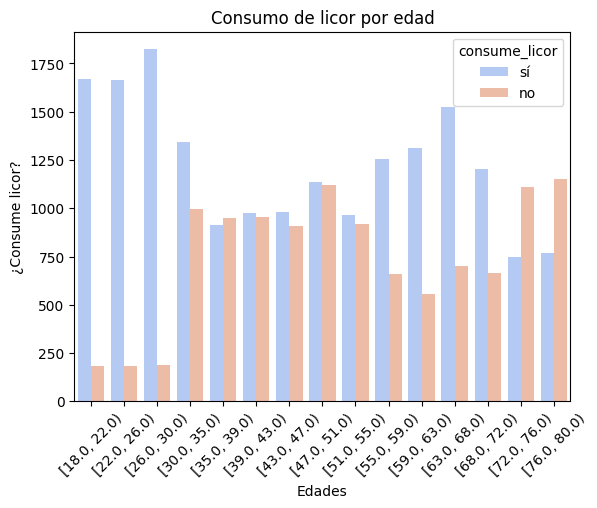

In [71]:
# Crafico para consumo de alcohol y edades
#Se recalculan los intervalos para todas las ciudades
K = int(1 + np.log2(len(dt_restaurant['edad'])))
intervals_aprox = np.round(np.linspace(dt_restaurant["edad"].min(), dt_restaurant["edad"].max(),K + 1,))
#Se crea la columa 'Rango edad' para contabilizar los que tienen esas edades
dt_restaurant['Rango_edad'] = pd.cut(dt_restaurant['edad'], bins=intervals_aprox, right=False)

consumo = dt_restaurant[dt_restaurant['consume_licor']== 'sí']['Rango_edad'].value_counts().index
Age_order = dt_restaurant['Rango_edad'].value_counts().sort_index().index
sns.countplot(dt_restaurant, x='Rango_edad', order=Age_order, hue='consume_licor', hue_order=['sí', 'no'],palette='coolwarm')
plt.title("Consumo de licor por edad")
plt.xlabel('Edades')
plt.ylabel('¿Consume licor?')
plt.xticks(rotation=45)
plt.show()


Los mayores consumos están en las edades 18-30 y 59 63